# 02 - Results synthesis

Reads the versioned outputs of `python -m src.main --stage all` (`results/metrics`, `results/figures`). Three blocks are kept strictly apart:

* **(a) real data** - the only benchmark;
* **(b) SYNTHETIC data** - scale and robustness only;
* **(c) TSTR** - models trained on synthetic data, evaluated on the real test split.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 50, 'display.width', 200, 'display.precision', 3)
FIG = ROOT / 'results' / 'figures'
MET = ROOT / 'results' / 'metrics'

## (a) Real data

Protocol: stratified 80/20 split (800 / 200 claims). On the 800 training claims, each model is tuned by Optuna (same 40-trial budget, same 5 folds, objective PR-AUC), then evaluated by 5x5 repeated stratified CV. The decision threshold minimises the expected cost on the training out-of-fold predictions. The test split is used once.

In [2]:
cv = pd.read_csv(MET / 'real_cv_summary.csv')
cv[['label', 'cv_pr_auc_mean', 'cv_pr_auc_sd', 'cv_roc_auc_mean', 'cv_brier_mean', 'oof_cost_threshold', 'fit_seconds']]

,label,cv_pr_auc_mean,cv_pr_auc_sd,cv_roc_auc_mean,cv_brier_mean,oof_cost_threshold,fit_seconds
0,CatBoost,0.707,0.054,0.878,0.102,0.15,4.772
1,Stacking (top-3 + logistic meta),0.704,0.062,0.871,0.104,0.13,64.334
2,Random forest,0.701,0.061,0.871,0.107,0.30,5.476
3,Gradient boosting (sklearn),0.695,0.057,0.861,0.106,0.19,0.890
4,Logistic regression (elastic net),0.693,0.054,0.876,0.125,0.19,0.555
5,XGBoost,0.683,0.059,0.872,0.122,0.36,0.270
6,MLP + embeddings (PyTorch),0.668,0.062,0.861,0.130,0.22,1.742
7,LightGBM,0.659,0.058,0.868,0.115,0.20,0.474
8,Logistic regression (no penalty),0.629,0.065,0.826,0.166,0.03,0.128


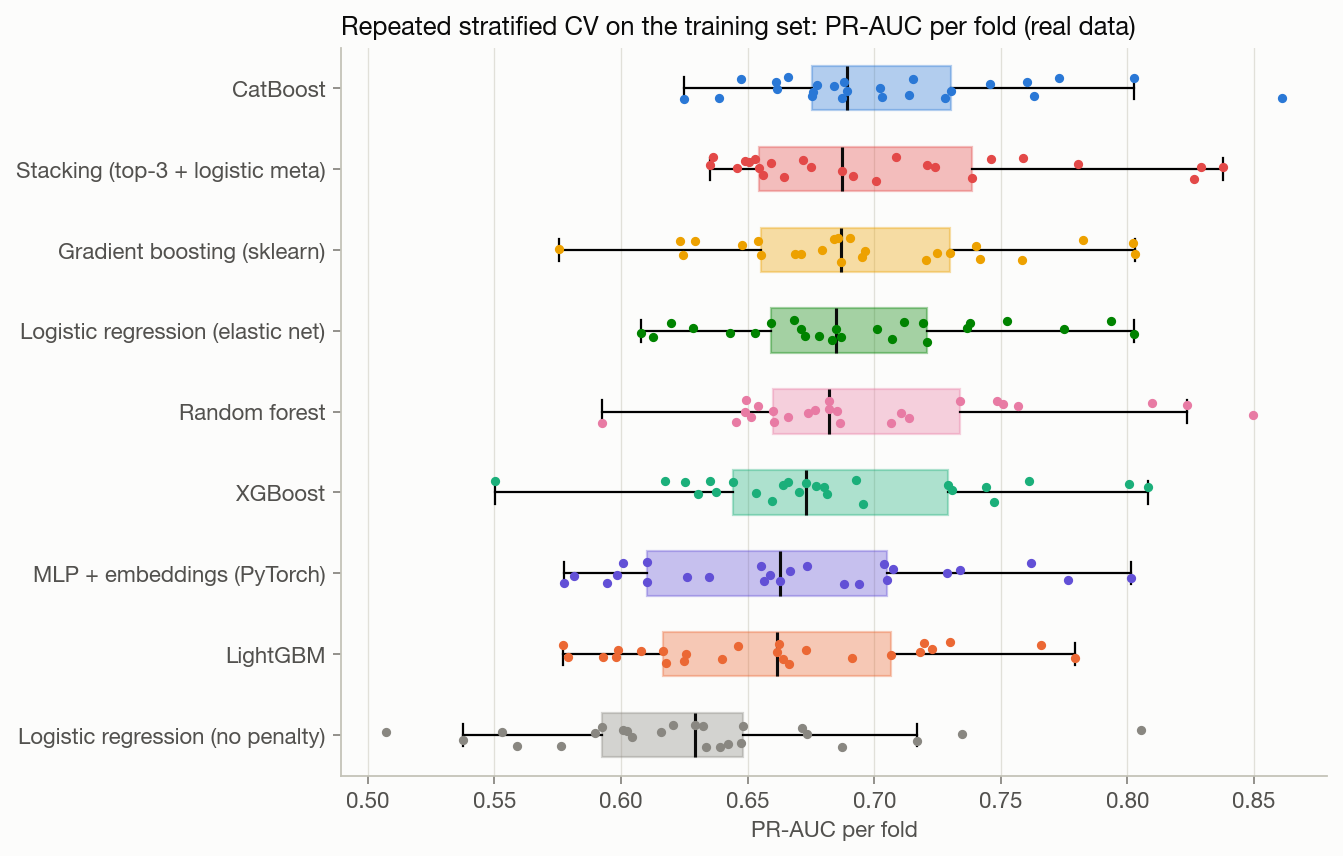

In [3]:
display(Image(FIG / 'real_cv_pr_auc_folds.png'))

In [4]:
display(Markdown((MET / 'real_results.md').read_text()))

| Model | CV PR-AUC (mean ± sd) | Test PR-AUC [95% CI] | Test ROC-AUC [95% CI] | F1 | Recall | Precision | MCC | Brier | Cost / claim (USD) |
|---|---|---|---|---|---|---|---|---|---|
| **CatBoost** | 0.707 ± 0.054 | 0.553 [0.463; 0.708] | 0.839 [0.769; 0.902] | 0.730 | 0.857 | 0.636 | 0.639 | 0.124 | 680 |
| Stacking (top-3 + logistic meta) | 0.704 ± 0.062 | 0.588 [0.482; 0.721] | 0.827 [0.747; 0.895] | 0.730 | 0.857 | 0.636 | 0.639 | 0.126 | 680 |
| Random forest | 0.701 ± 0.061 | 0.600 [0.489; 0.736] | 0.827 [0.748; 0.897] | 0.718 | 0.857 | 0.618 | 0.622 | 0.123 | 690 |
| Gradient boosting (sklearn) | 0.695 ± 0.057 | 0.592 [0.483; 0.726] | 0.837 [0.766; 0.899] | 0.730 | 0.857 | 0.636 | 0.639 | 0.120 | 680 |
| Logistic regression (elastic net) | 0.693 ± 0.054 | 0.524 [0.434; 0.669] | 0.818 [0.743; 0.884] | 0.609 | 0.857 | 0.472 | 0.472 | 0.152 | 795 |
| XGBoost | 0.683 ± 0.059 | 0.512 [0.432; 0.657] | 0.832 [0.763; 0.894] | 0.726 | 0.837 | 0.641 | 0.631 | 0.143 | 720 |
| MLP + embeddings (PyTorch) | 0.668 ± 0.062 | 0.537 [0.447; 0.682] | 0.840 [0.777; 0.896] | 0.621 | 0.837 | 0.494 | 0.488 | 0.146 | 815 |
| LightGBM | 0.659 ± 0.058 | 0.520 [0.439; 0.665] | 0.830 [0.753; 0.897] | 0.707 | 0.837 | 0.612 | 0.606 | 0.140 | 735 |
| Logistic regression (no penalty) | 0.629 ± 0.065 | 0.499 [0.402; 0.646] | 0.771 [0.686; 0.844] | 0.503 | 0.735 | 0.383 | 0.302 | 0.175 | 1,120 |

Trivial policies on the test set: investigate nothing = 2,450 USD/claim, investigate all = 1,000 USD/claim.

Reference model (best mean CV PR-AUC): CatBoost. Exported model: CatBoost.

| Model vs reference | Δ CV PR-AUC | corrected t-test p (Holm) | Δ test PR-AUC [95% CI] | bootstrap p (Holm) | McNemar p (Holm) |
|---|---|---|---|---|---|
| Stacking (top-3 + logistic meta) | -0.003 | 1.000 | +0.035 [-0.027; +0.078] | 1.000 | 1.000 |
| Random forest | -0.006 | 1.000 | +0.047 [-0.046; +0.113] | 1.000 | 1.000 |
| Gradient boosting (sklearn) | -0.012 | 1.000 | +0.039 [-0.041; +0.094] | 1.000 | 1.000 |
| Logistic regression (elastic net) | -0.014 | 1.000 | -0.029 [-0.110; +0.052] | 1.000 | 0.000 |
| XGBoost | -0.024 | 1.000 | -0.041 [-0.115; +0.022] | 1.000 | 1.000 |
| MLP + embeddings (PyTorch) | -0.039 | 1.000 | -0.016 [-0.092; +0.065] | 1.000 | 0.000 |
| LightGBM | -0.048 | 0.220 | -0.033 [-0.106; +0.041] | 1.000 | 1.000 |
| Logistic regression (no penalty) | -0.078 | 0.312 | -0.054 [-0.144; +0.032] | 1.000 | 0.000 |

| Calibration (test) | Brier | PR-AUC |
|---|---|---|
| CatBoost (uncalibrated) | 0.1237 | 0.553 |
| Logistic regression (no penalty) (uncalibrated) | 0.1748 | 0.499 |
| CatBoost (sigmoid) | 0.1242 | 0.576 |
| CatBoost (isotonic) | 0.1222 | 0.576 |


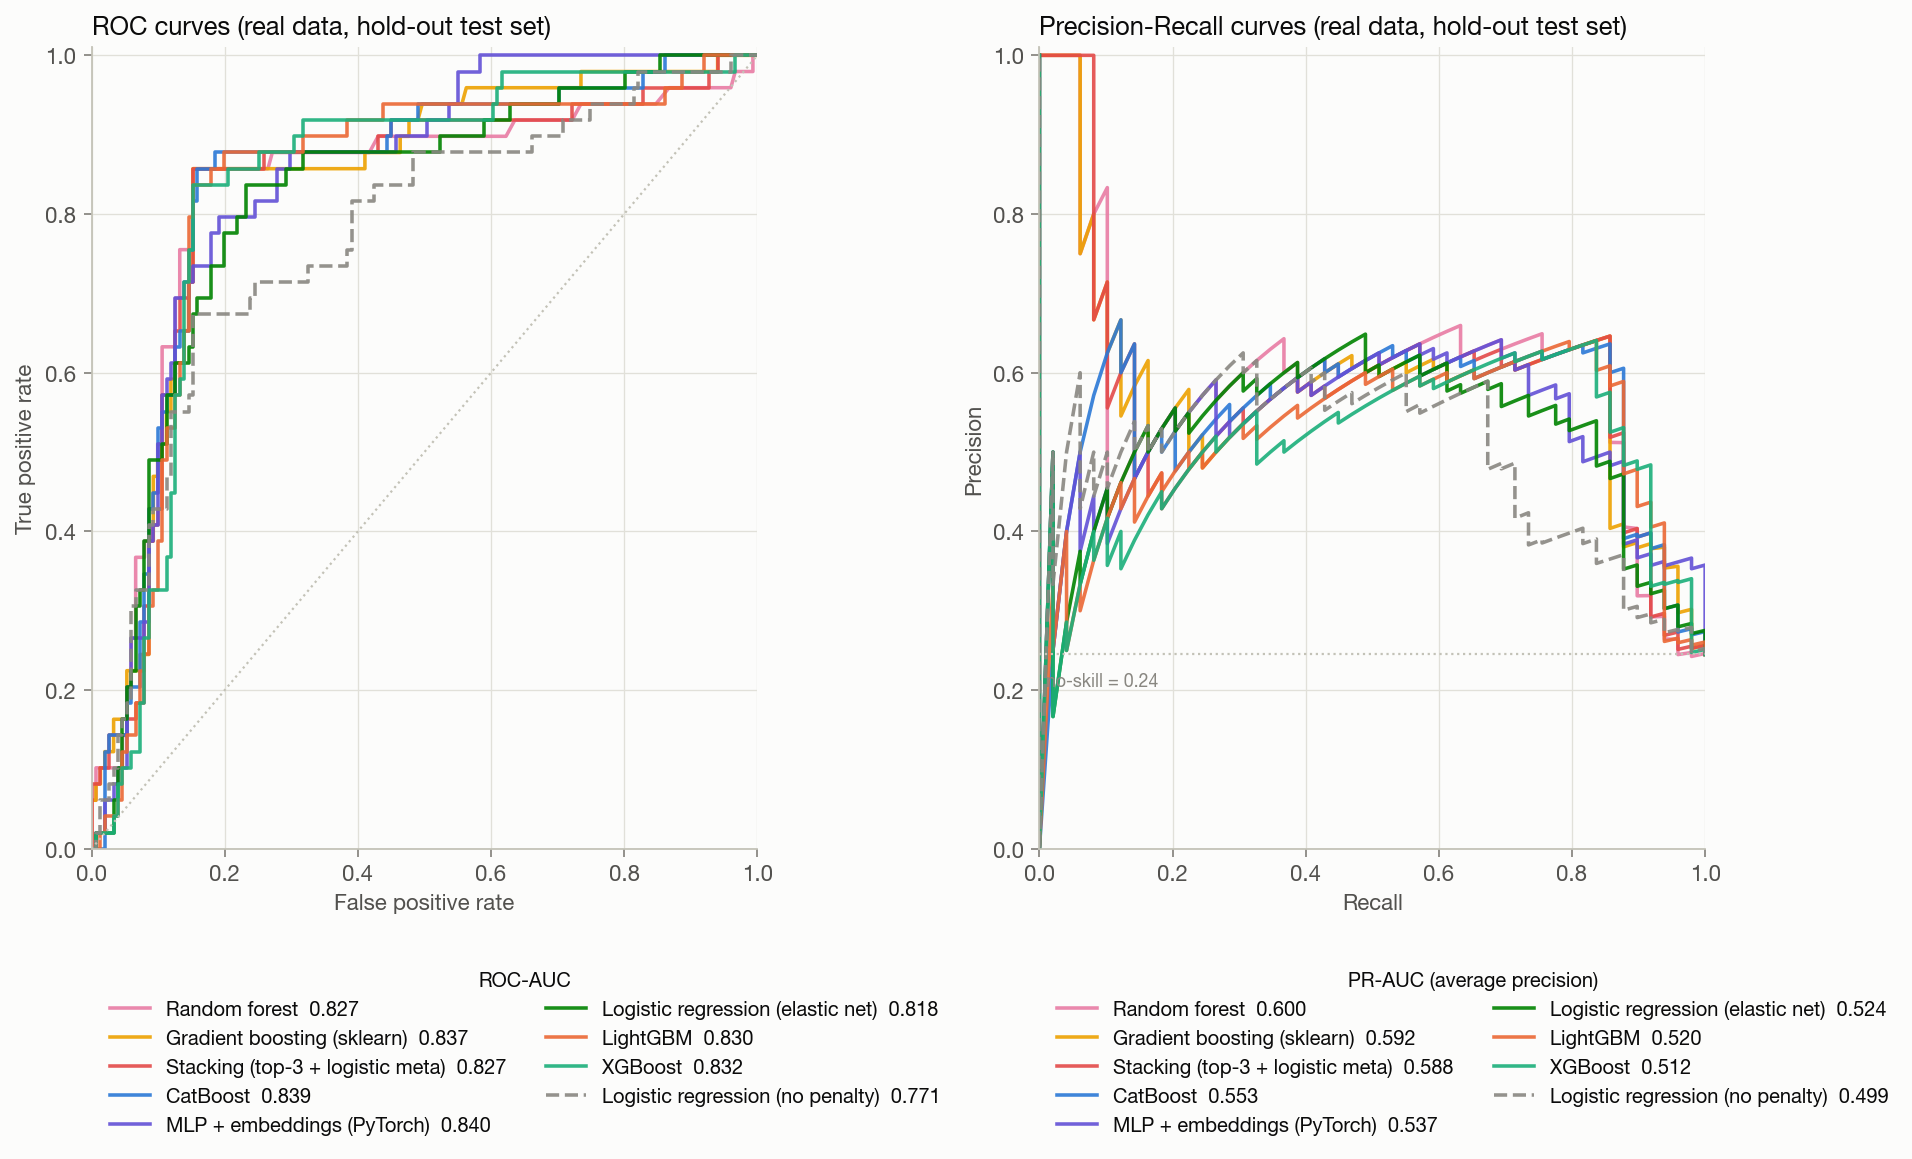

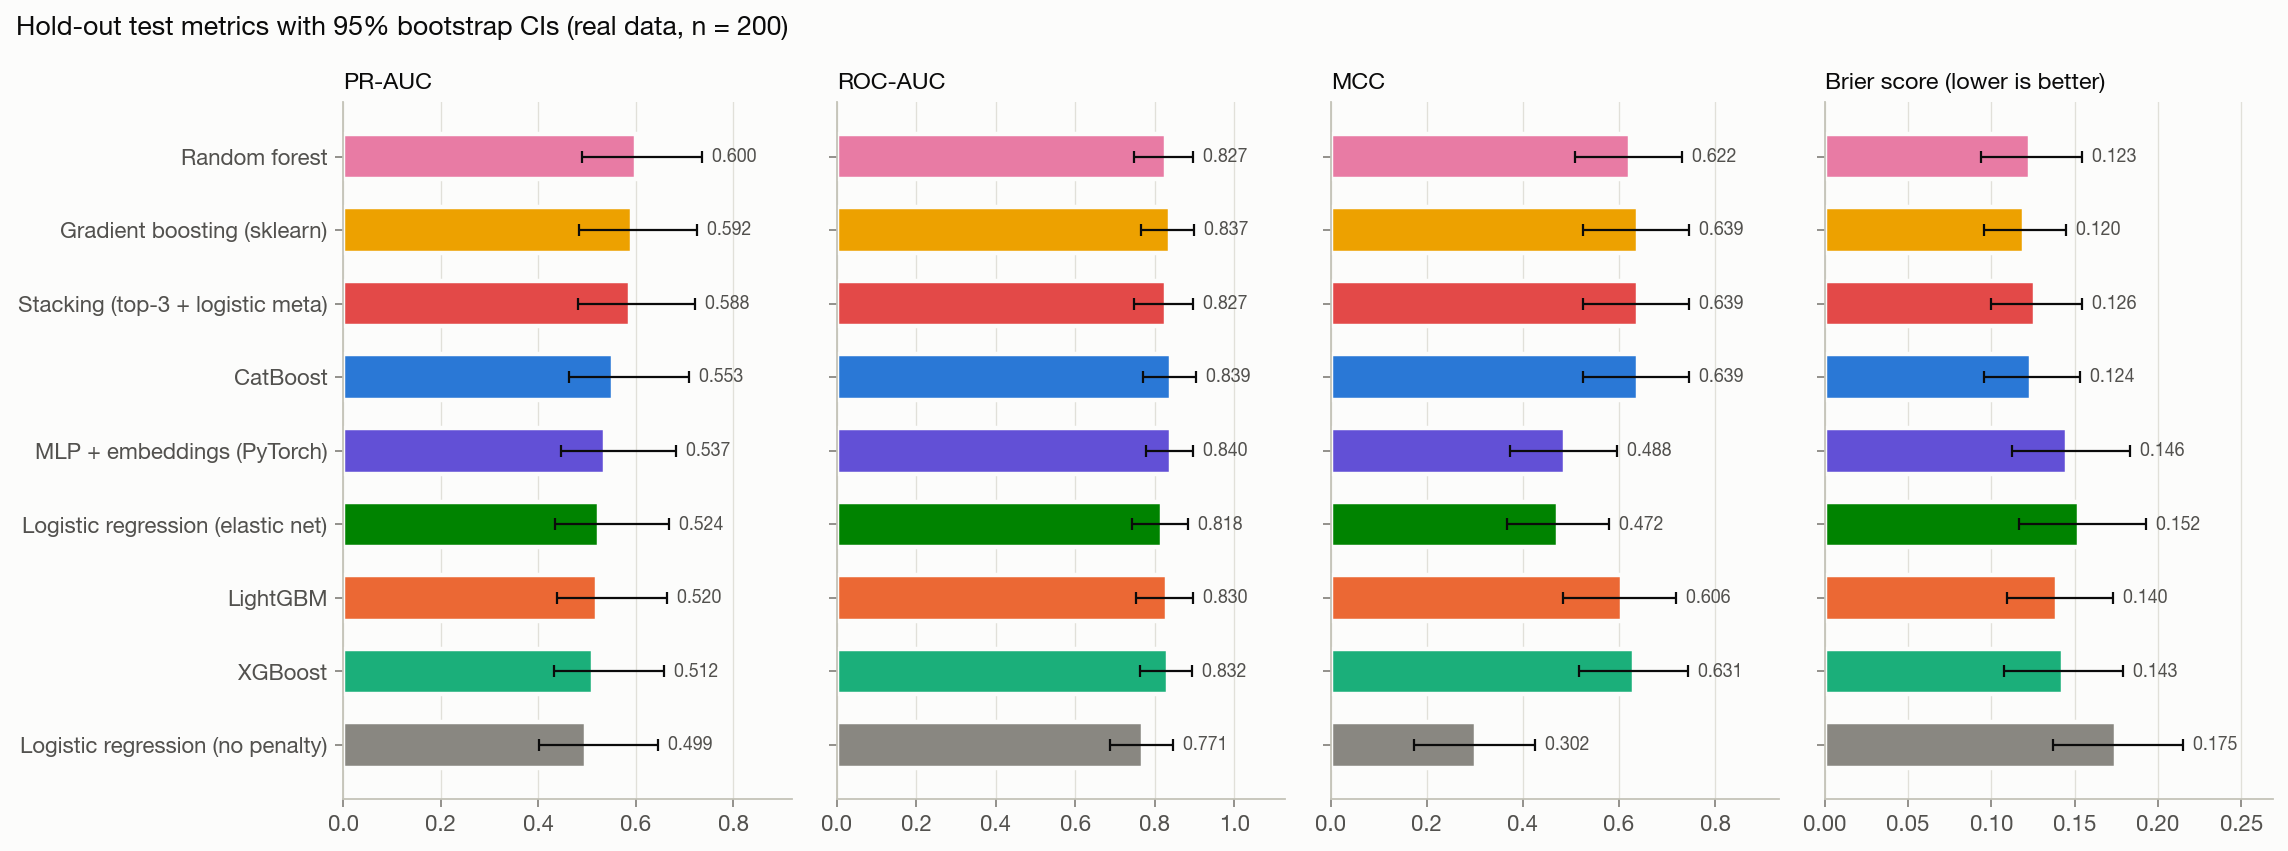

In [5]:
display(Image(FIG / 'real_roc_pr_curves.png'))
display(Image(FIG / 'real_metrics_ci.png'))

### Statistical comparison against the reference model

In [6]:
tests = pd.read_csv(MET / 'real_model_comparison_tests.csv')
tests[['model', 'cv_pr_auc_diff', 'cv_ttest_p_holm', 'test_pr_auc_diff', 'test_pr_auc_boot_p_holm', 'mcnemar_p_holm']]

,model,cv_pr_auc_diff,cv_ttest_p_holm,test_pr_auc_diff,test_pr_auc_boot_p_holm,mcnemar_p_holm
0,stacking,0.003,1.000,-0.035,1.0,1.000e+00
1,random_forest,0.006,1.000,-0.047,1.0,1.000e+00
2,gradient_boosting,0.012,1.000,-0.039,1.0,1.000e+00
3,logreg_enet,0.014,1.000,0.029,1.0,1.067e-04
4,xgboost,0.024,1.000,0.041,1.0,1.000e+00
5,mlp,0.039,1.000,0.016,1.0,1.259e-04
6,lightgbm,0.048,0.220,0.033,1.0,1.000e+00
7,logreg,0.078,0.312,0.054,1.0,3.698e-09


### Imbalance strategies and feature ablations (5x5 CV on the training split)

In [7]:
pd.read_csv(MET / 'real_imbalance_strategies.csv')

,model,strategy,tuned_choice,pr_auc_mean,roc_auc_mean,brier_mean,pr_auc_sd,roc_auc_sd,brier_sd
0,logreg_enet,none,False,0.687,0.876,0.114,0.051,0.026,0.010
1,logreg_enet,balanced,True,0.693,0.876,0.125,0.054,0.026,0.013
2,logreg_enet,smote,False,0.682,0.869,0.129,0.054,0.025,0.013
3,random_forest,none,False,0.685,0.863,0.109,0.052,0.029,0.010
4,random_forest,balanced,False,0.682,0.865,0.109,0.060,0.032,0.011
5,random_forest,smote,True,0.701,0.871,0.107,0.061,0.029,0.011
6,xgboost,none,False,0.659,0.862,0.118,0.073,0.042,0.016
7,xgboost,balanced,True,0.683,0.872,0.122,0.059,0.031,0.013
8,xgboost,smote,False,0.666,0.872,0.116,0.057,0.027,0.011
9,lightgbm,none,False,0.499,0.757,0.156,0.061,0.037,0.012


In [8]:
pd.read_csv(MET / 'real_feature_ablation.csv')

,model,variant,pr_auc_mean,pr_auc_sd,roc_auc_mean,roc_auc_sd
0,catboost,all features (default),0.707,0.054,0.878,0.032
1,catboost,+ total_claim_amount (redundant),0.705,0.052,0.875,0.031
2,catboost,- all claim-amount features,0.716,0.054,0.878,0.029
3,catboost,- insured_hobbies,0.499,0.049,0.750,0.040
4,catboost,- incident_severity,0.539,0.050,0.711,0.036
5,logreg_enet,all features (default),0.693,0.054,0.876,0.026
6,logreg_enet,+ total_claim_amount (redundant),0.693,0.054,0.876,0.026
7,logreg_enet,- all claim-amount features,0.697,0.054,0.878,0.026
8,logreg_enet,- insured_hobbies,0.509,0.057,0.752,0.035
9,logreg_enet,- incident_severity,0.516,0.051,0.710,0.039


### Calibration and business cost

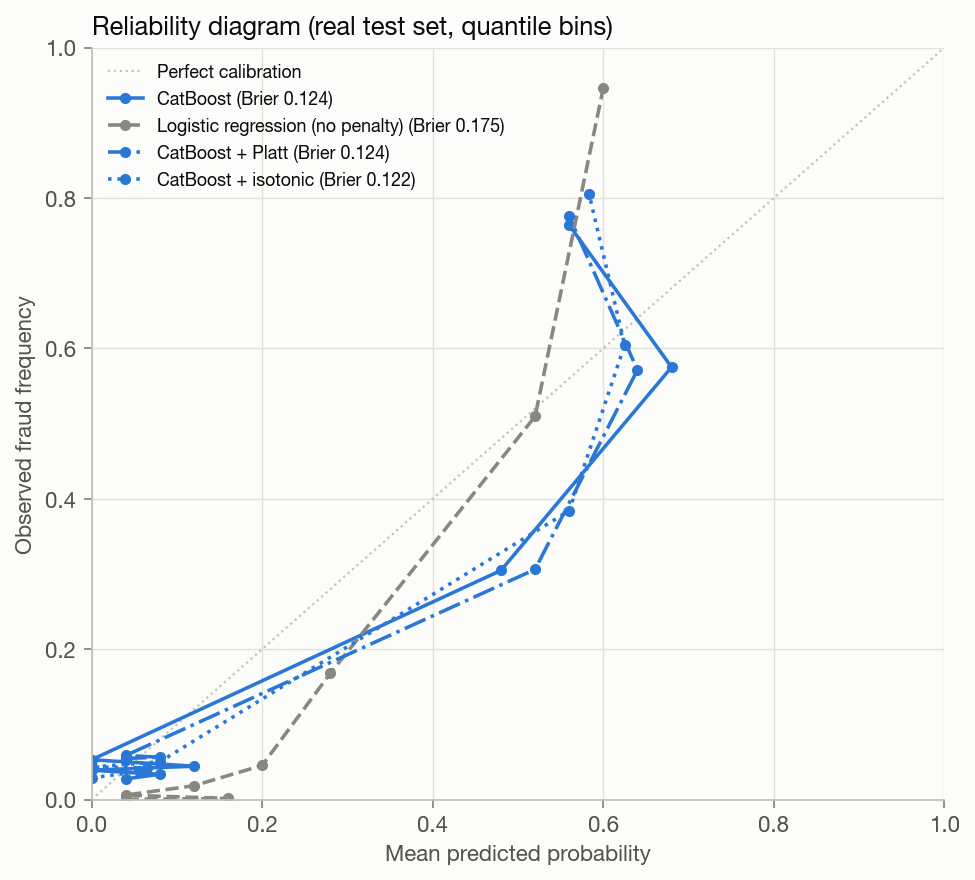

,model,method,brier,pr_auc
0,catboost,uncalibrated,0.124,0.553
1,logreg,uncalibrated,0.175,0.499
2,catboost,sigmoid,0.124,0.576
3,catboost,isotonic,0.122,0.576


In [9]:
display(Image(FIG / 'real_calibration.png'))
pd.read_csv(MET / 'real_calibration.csv')

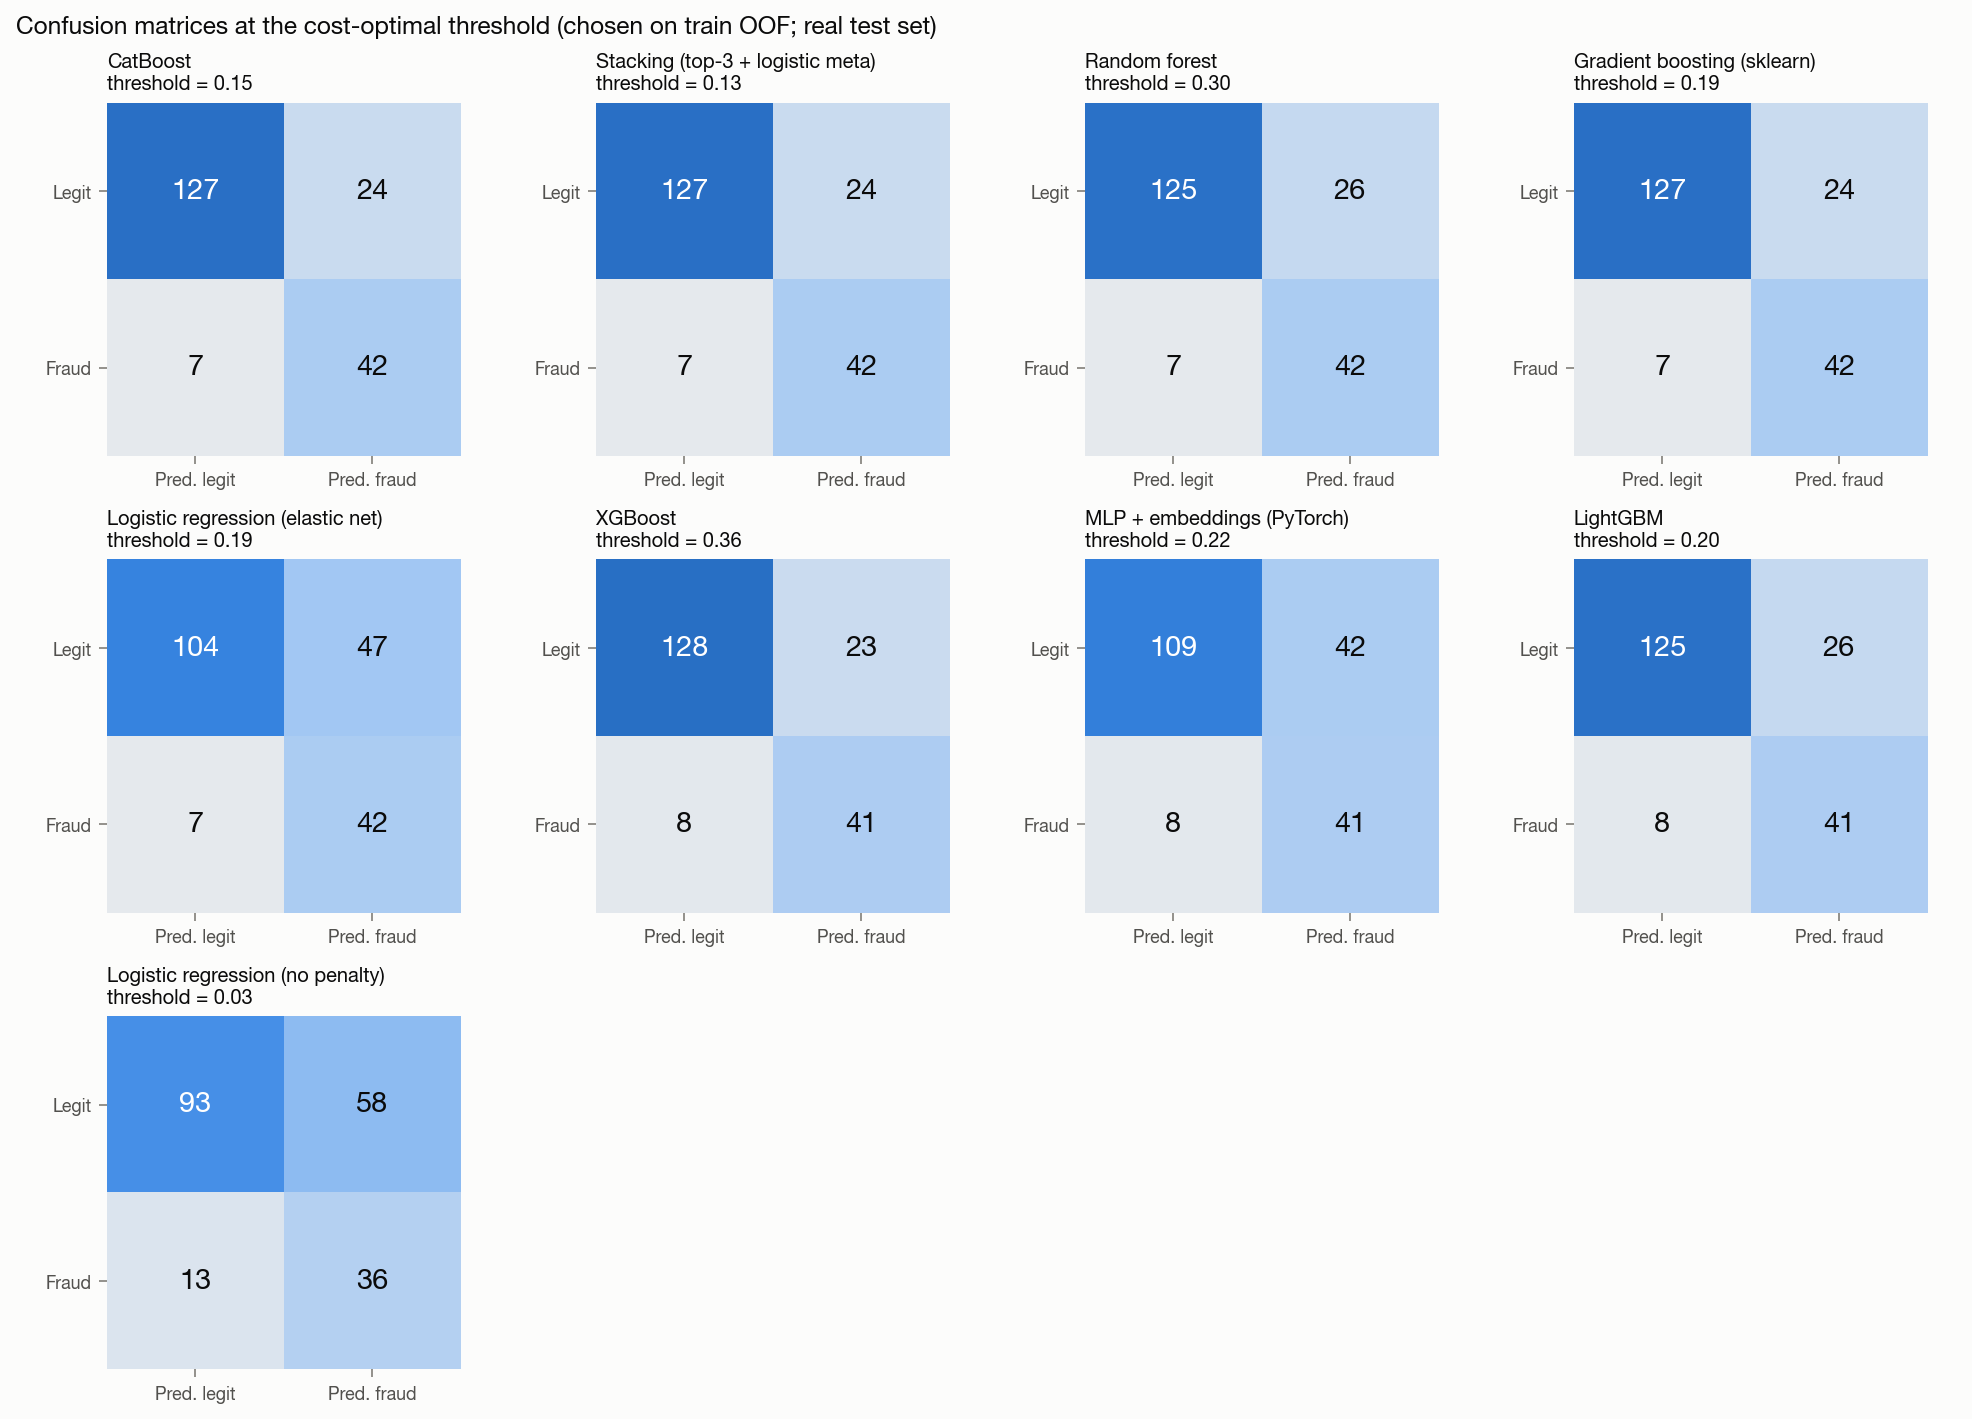

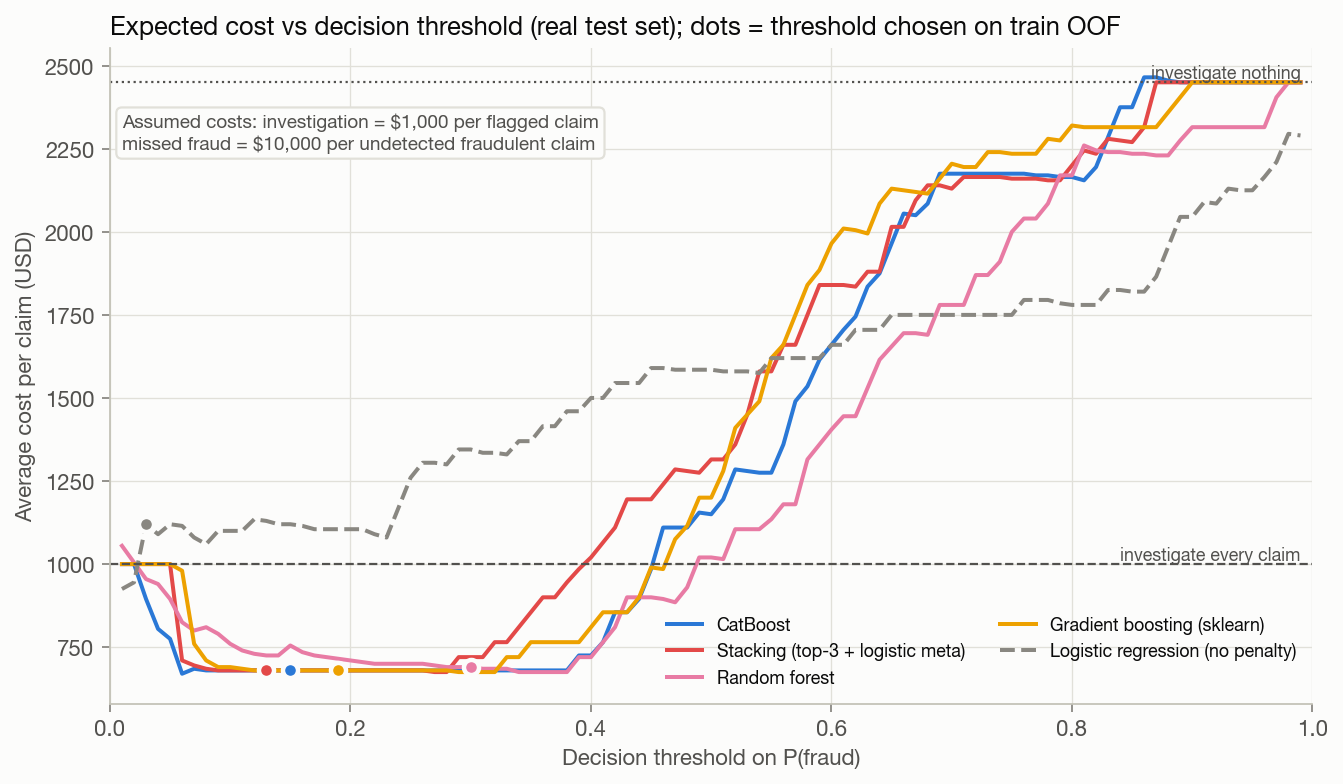

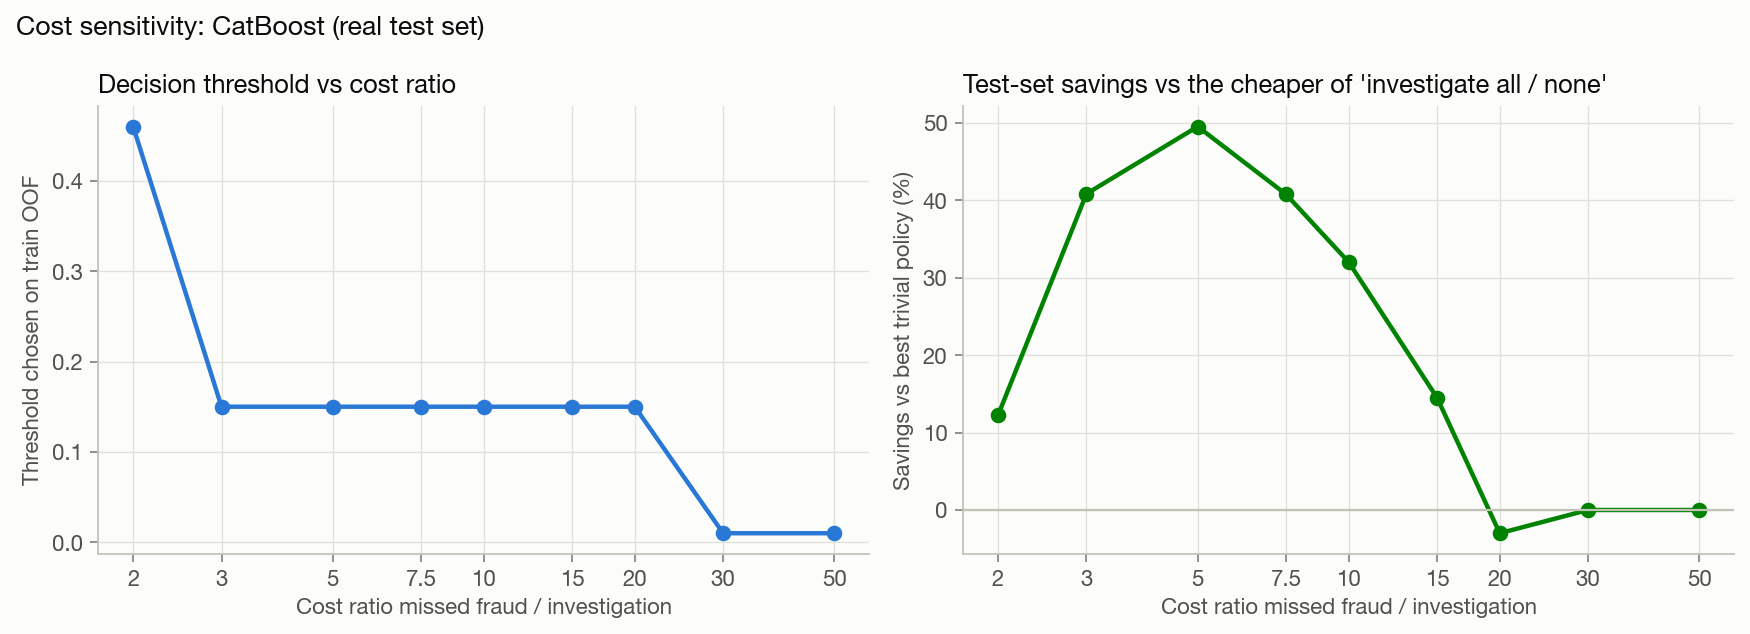

,cost_ratio,threshold,model_cost,best_trivial_cost,best_trivial_policy,savings_pct
0,2.0,0.46,430.0,490.0,investigate_none,12.245
1,3.0,0.15,435.0,735.0,investigate_none,40.816
2,5.0,0.15,505.0,1000.0,investigate_all,49.500
3,7.5,0.15,592.5,1000.0,investigate_all,40.750
4,10.0,0.15,680.0,1000.0,investigate_all,32.000
5,15.0,0.15,855.0,1000.0,investigate_all,14.500
6,20.0,0.15,1030.0,1000.0,investigate_all,-3.000
7,30.0,0.01,1000.0,1000.0,investigate_all,0.000
8,50.0,0.01,1000.0,1000.0,investigate_all,0.000


In [10]:
display(Image(FIG / 'real_confusion_matrices.png'))
display(Image(FIG / 'real_cost_vs_threshold.png'))
display(Image(FIG / 'real_cost_sensitivity.png'))
pd.read_csv(MET / 'real_cost_sensitivity.csv')

### Interpretability

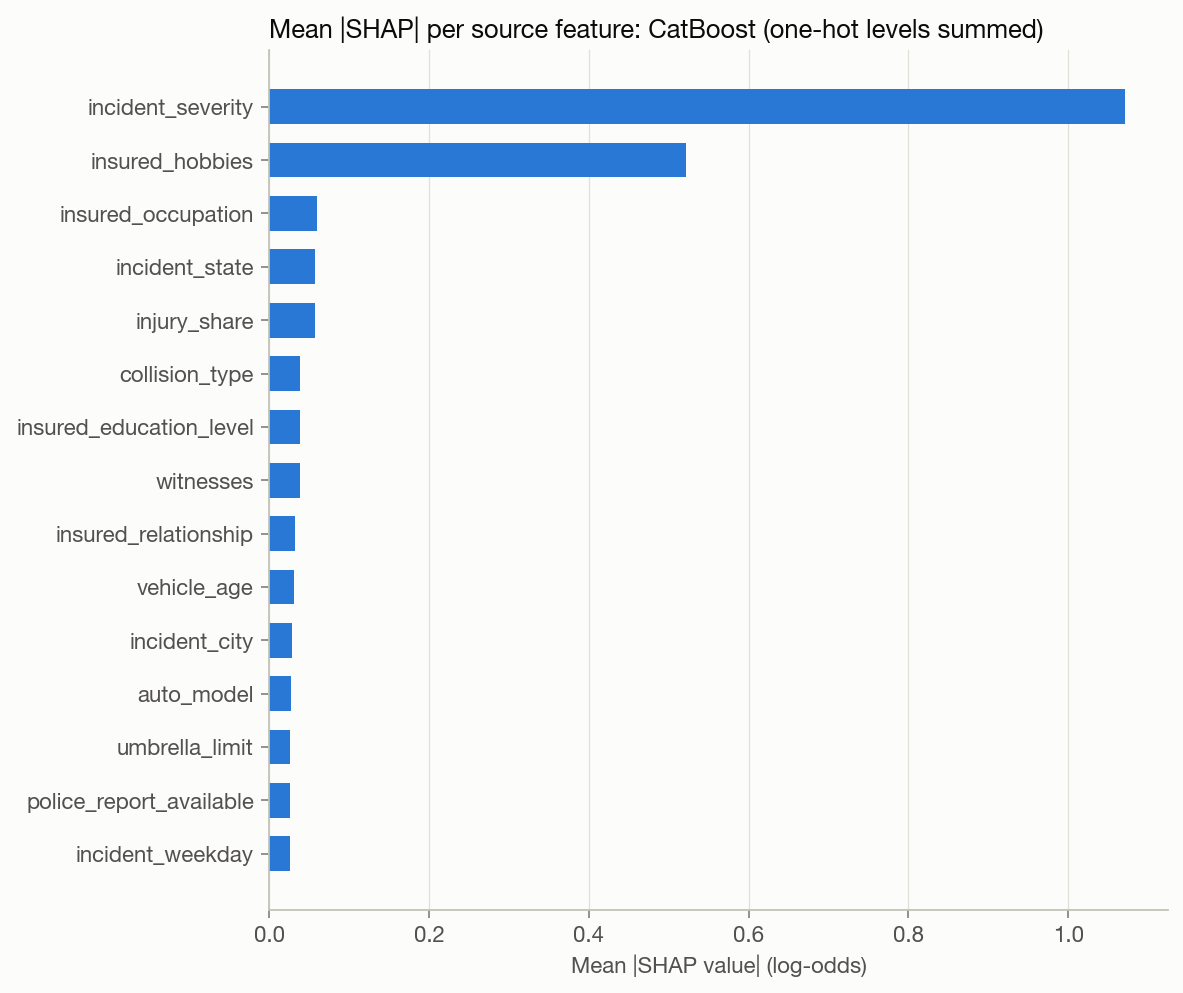

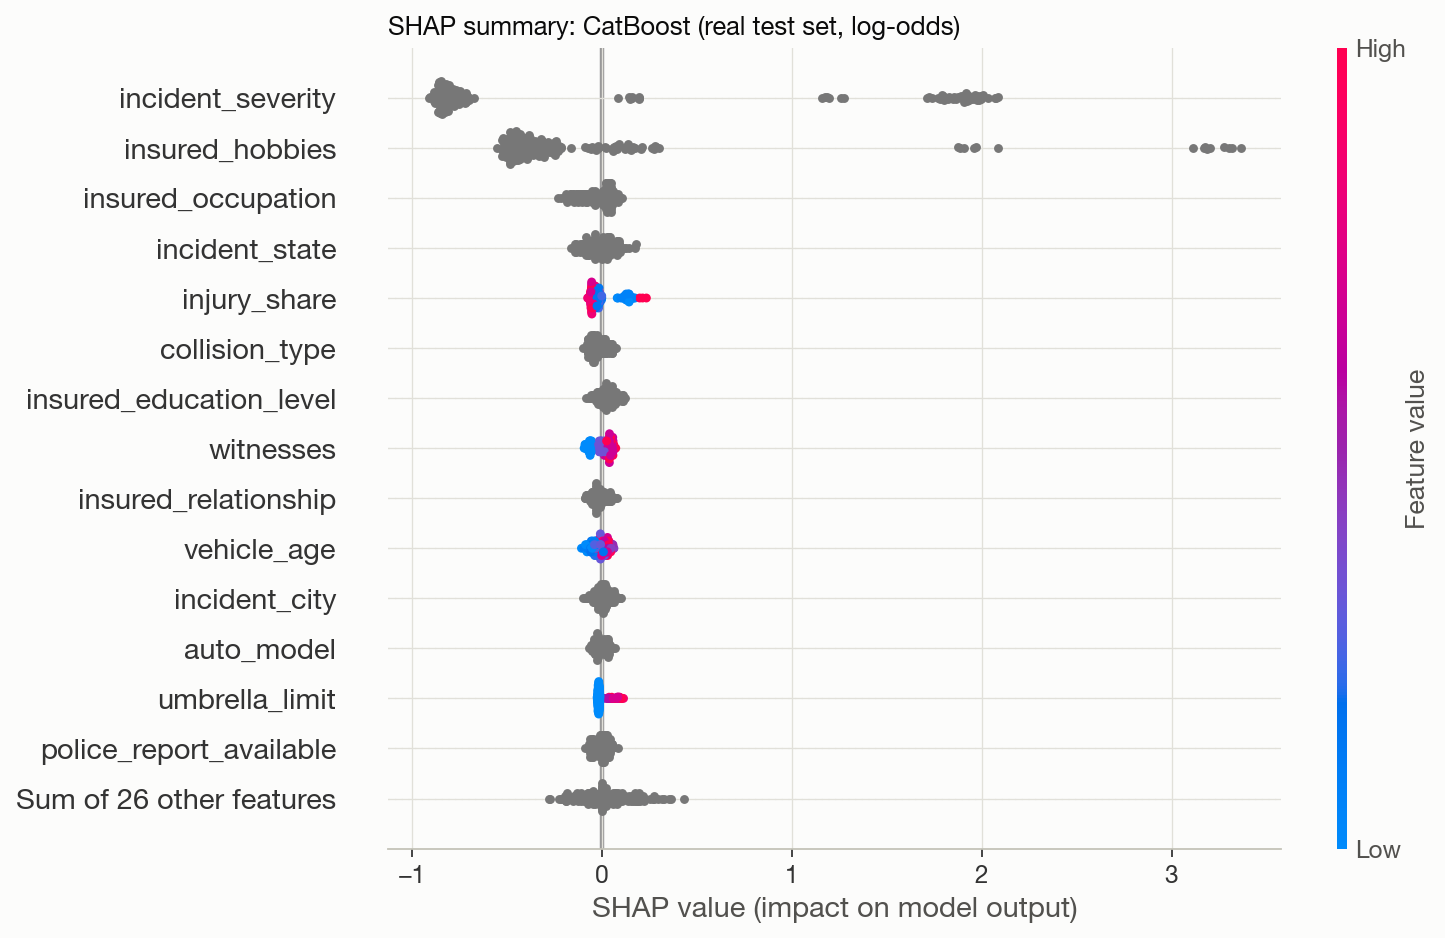

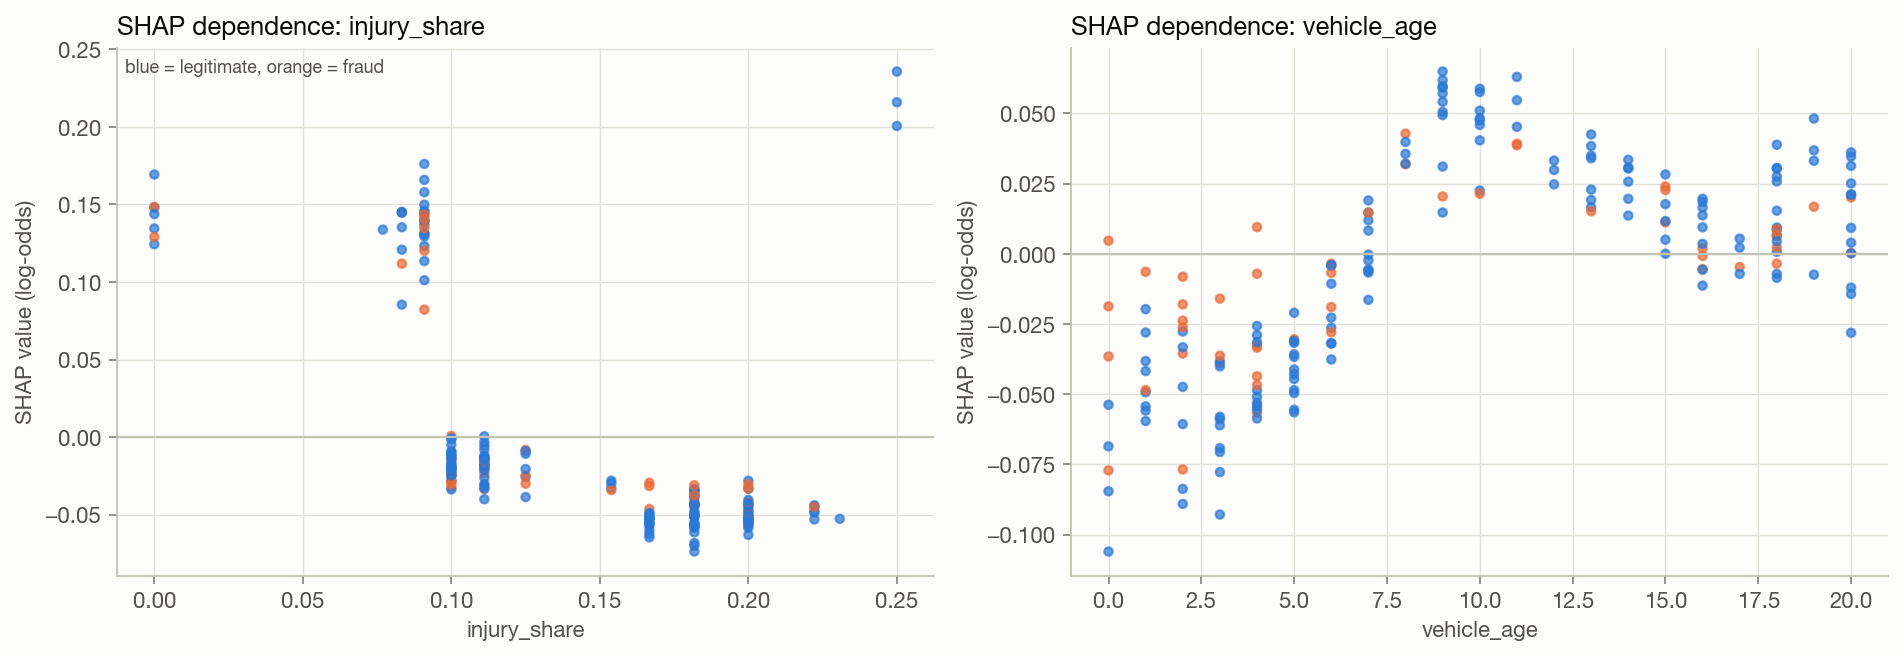

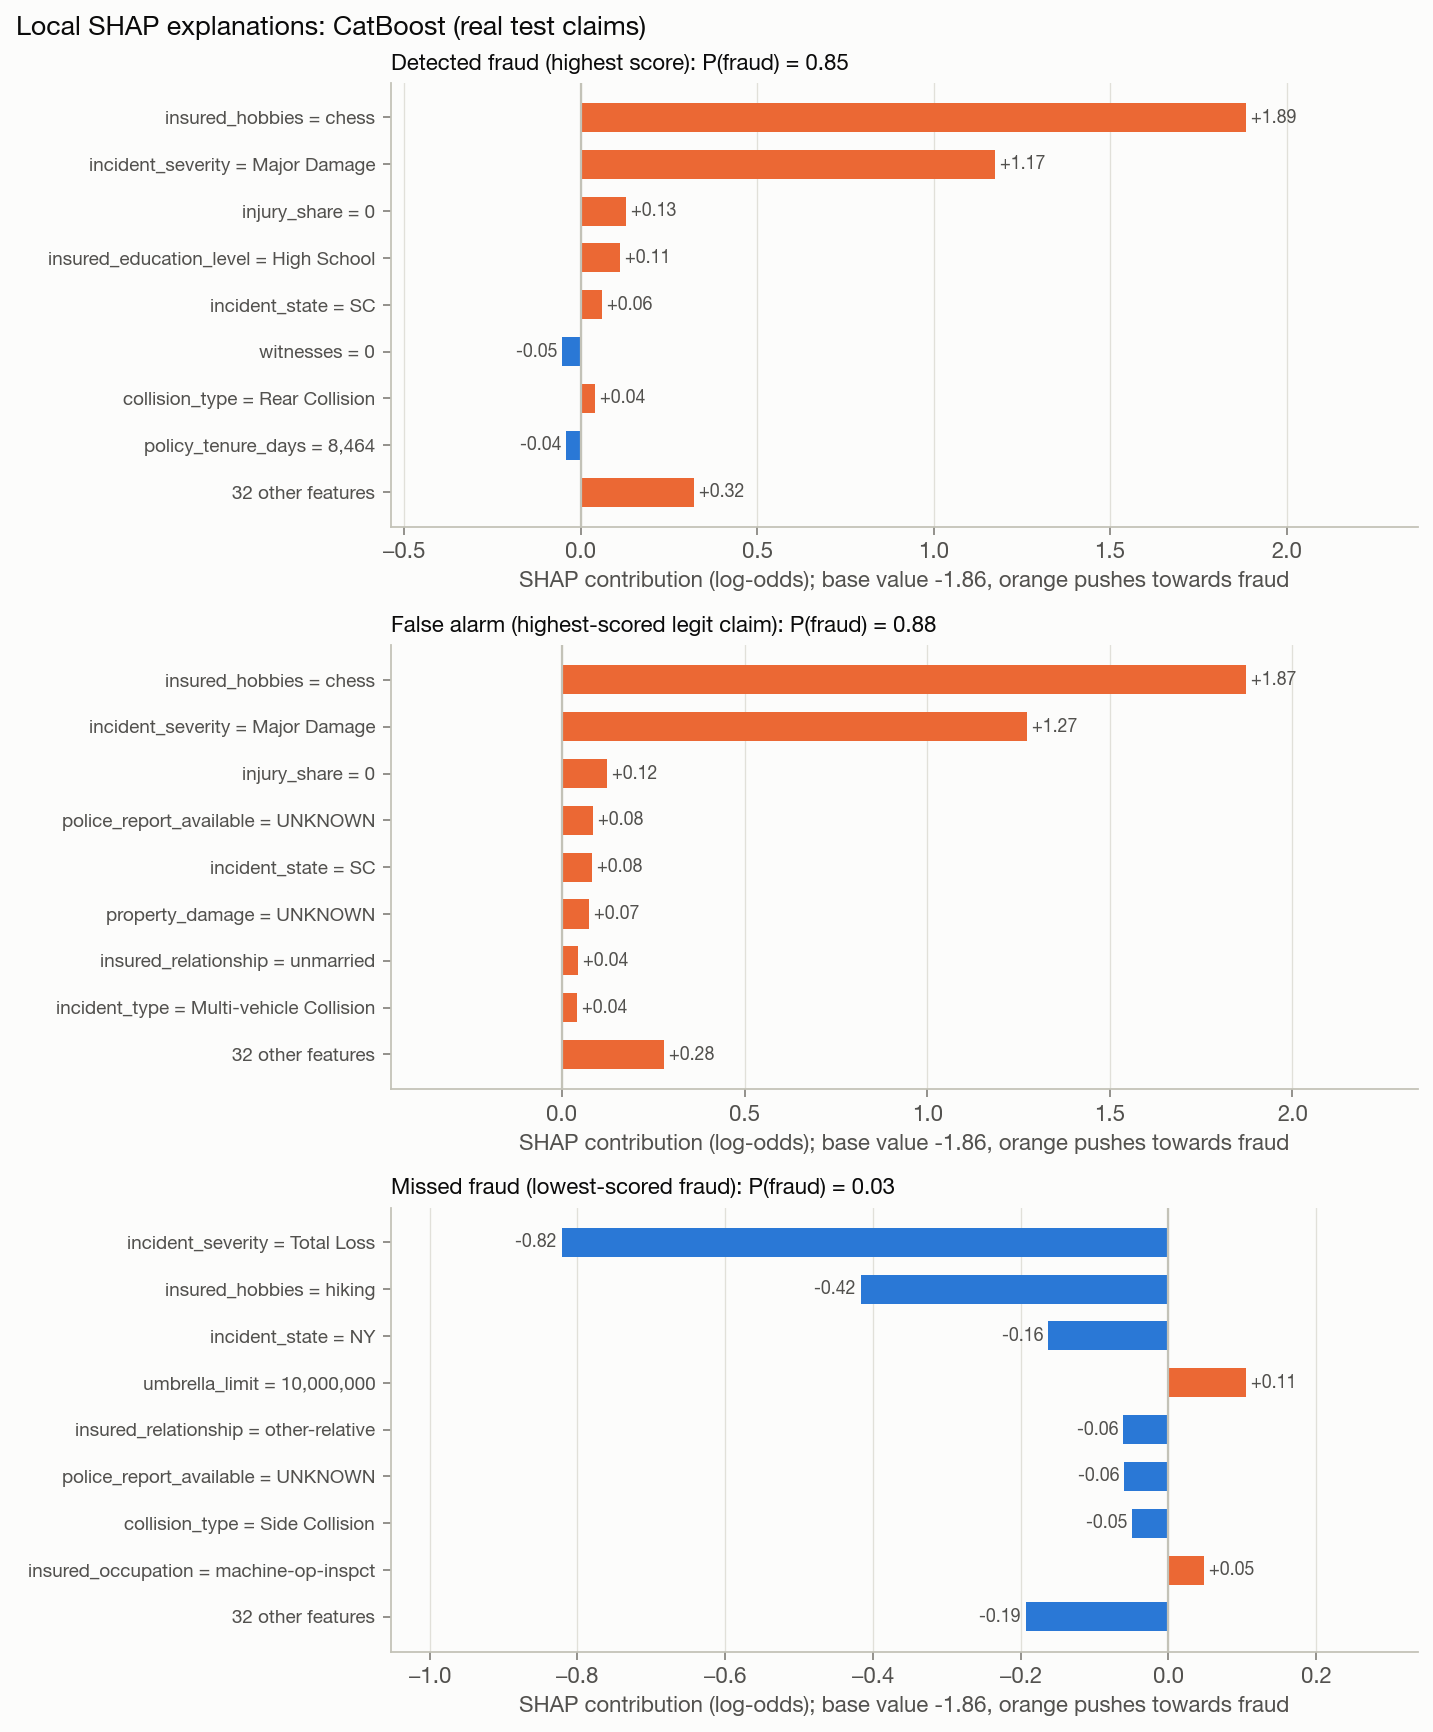

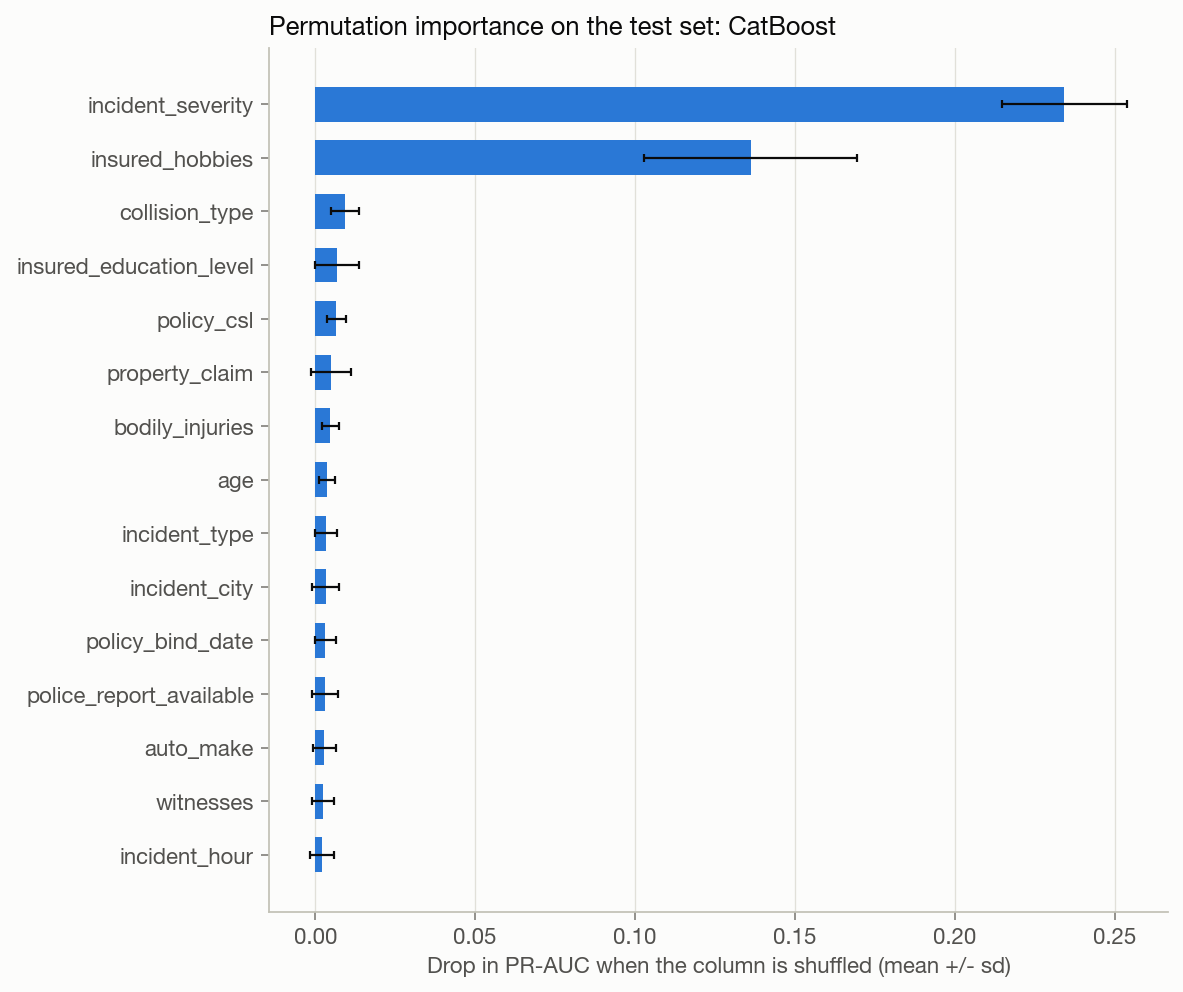

In [11]:
display(Image(FIG / 'real_shap_by_feature.png'))
display(Image(FIG / 'real_shap_beeswarm.png'))
display(Image(FIG / 'real_shap_dependence.png'))
display(Image(FIG / 'real_shap_local.png'))
display(Image(FIG / 'real_permutation_importance.png'))

### Learning curves and neural network training

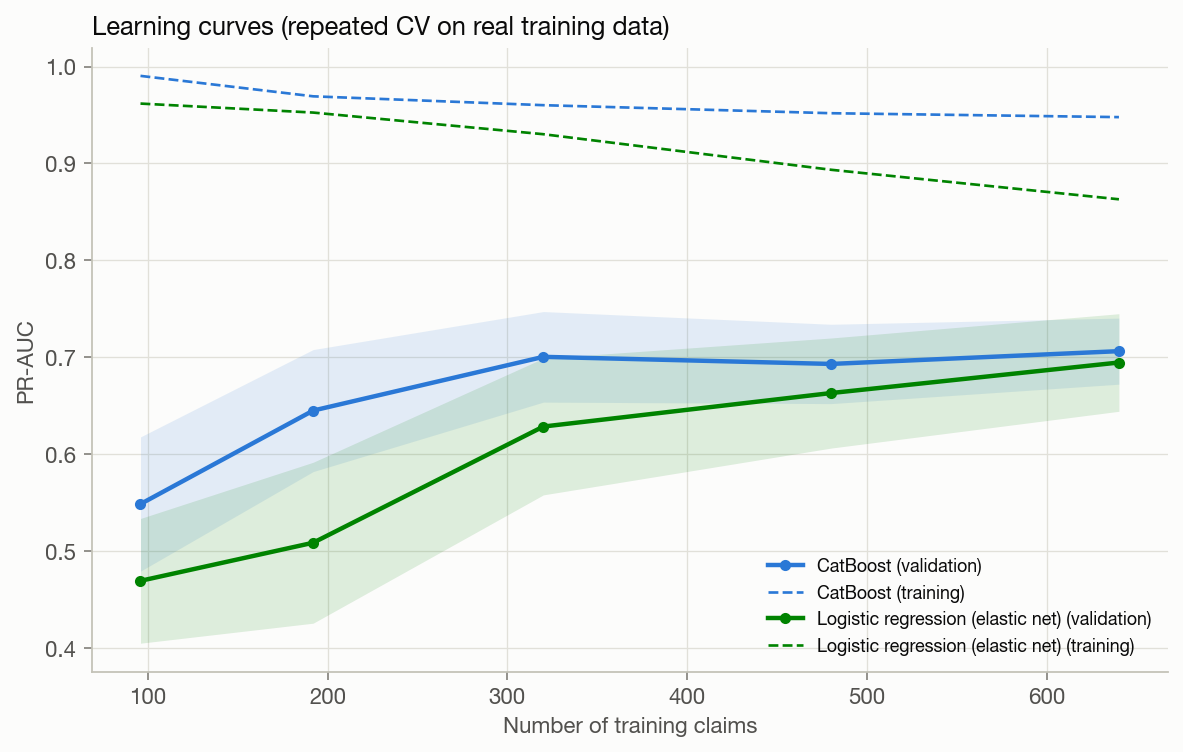

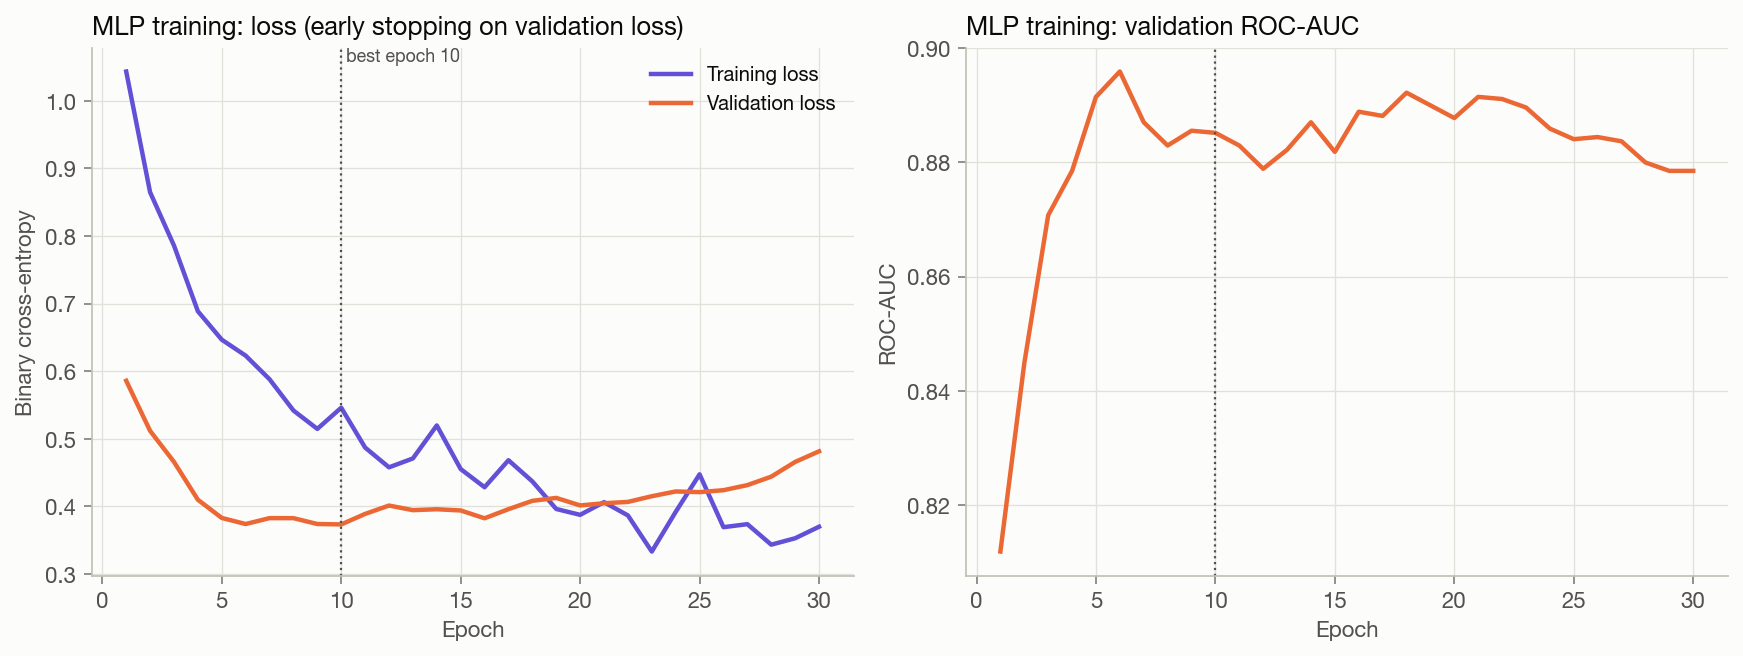

In [12]:
display(Image(FIG / 'real_learning_curves.png'))
display(Image(FIG / 'real_mlp_loss_curves.png'))

## (b) SYNTHETIC data - generator quality

All generators are fitted on the 800 real training claims only.

In [13]:
q = pd.read_csv(MET / 'synthetic_quality.csv').set_index('generator')
q.T

generator,gaussian_copula_custom,sdv_gaussian_copula,sdv_ctgan
fit_seconds,0.113,7.420,86.248
sample_seconds_per_100k,2.063,32.609,10.503
fraud_rate,0.248,0.243,0.329
ks_numeric_mean,0.010,0.190,0.176
tvd_categorical_mean,0.008,0.011,0.056
spearman_mean_abs_diff,0.014,0.018,0.065
cramers_v_mean_abs_diff,0.085,0.100,0.107
target_assoc_mean_abs_diff,0.005,0.114,0.130
rule_violation_rate_raw,0.214,0.318,0.314
detection_auc,0.829,1.000,0.997


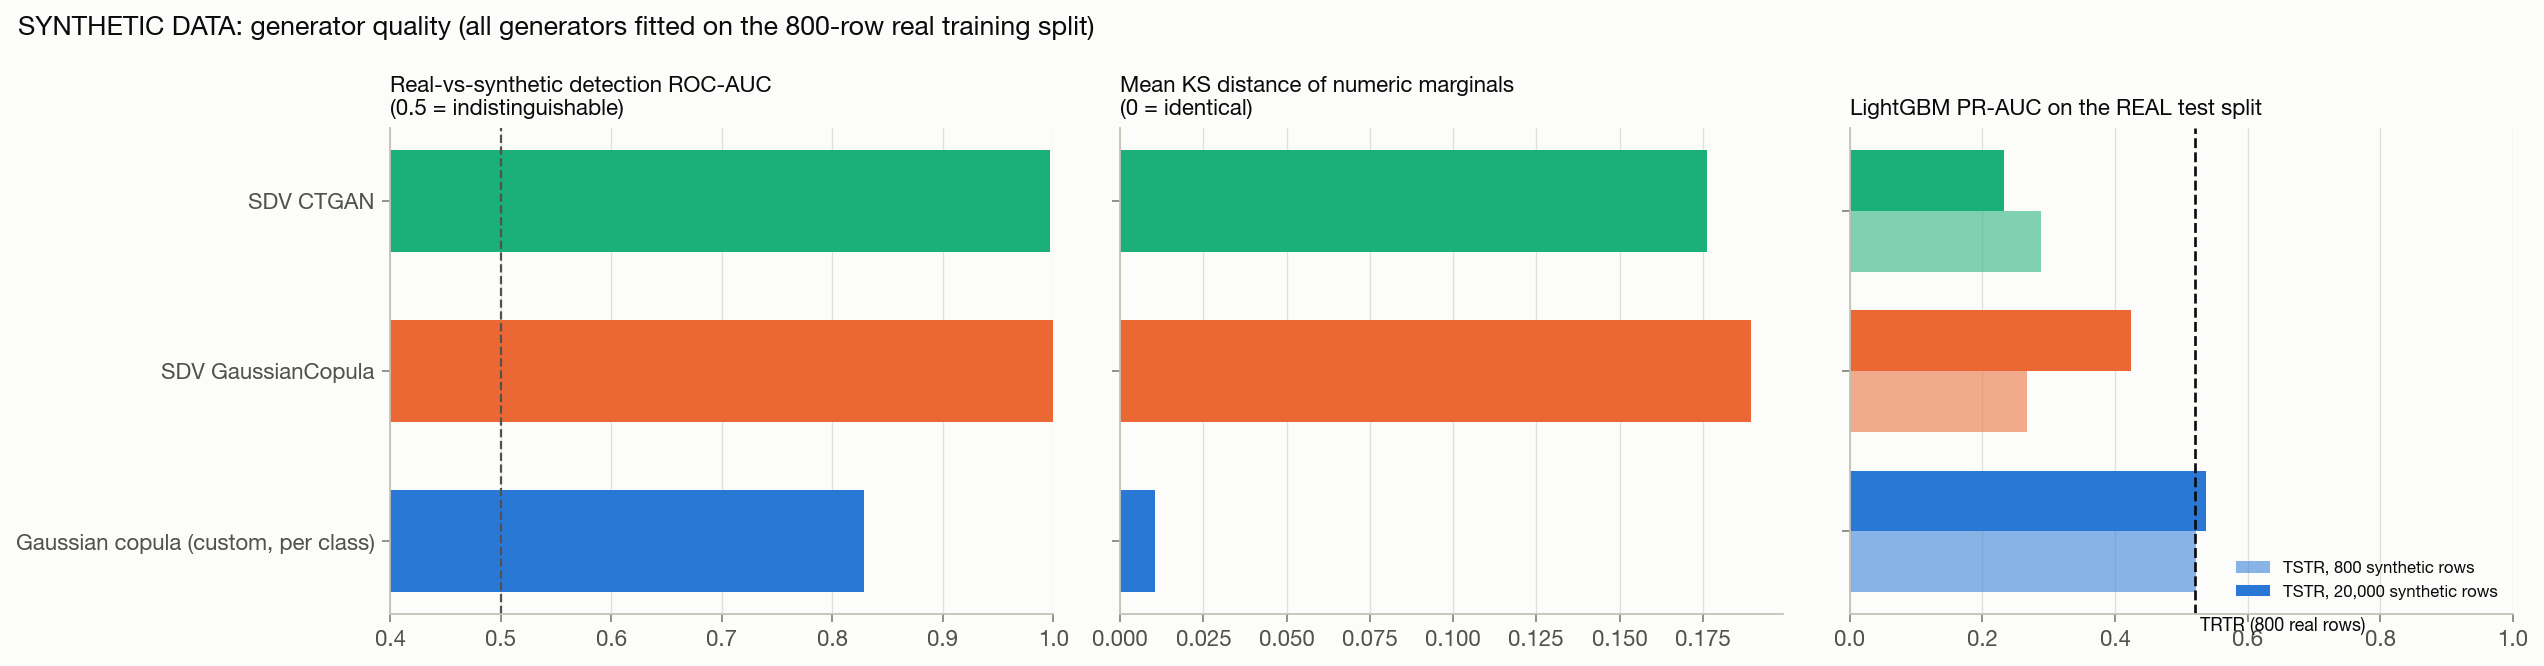

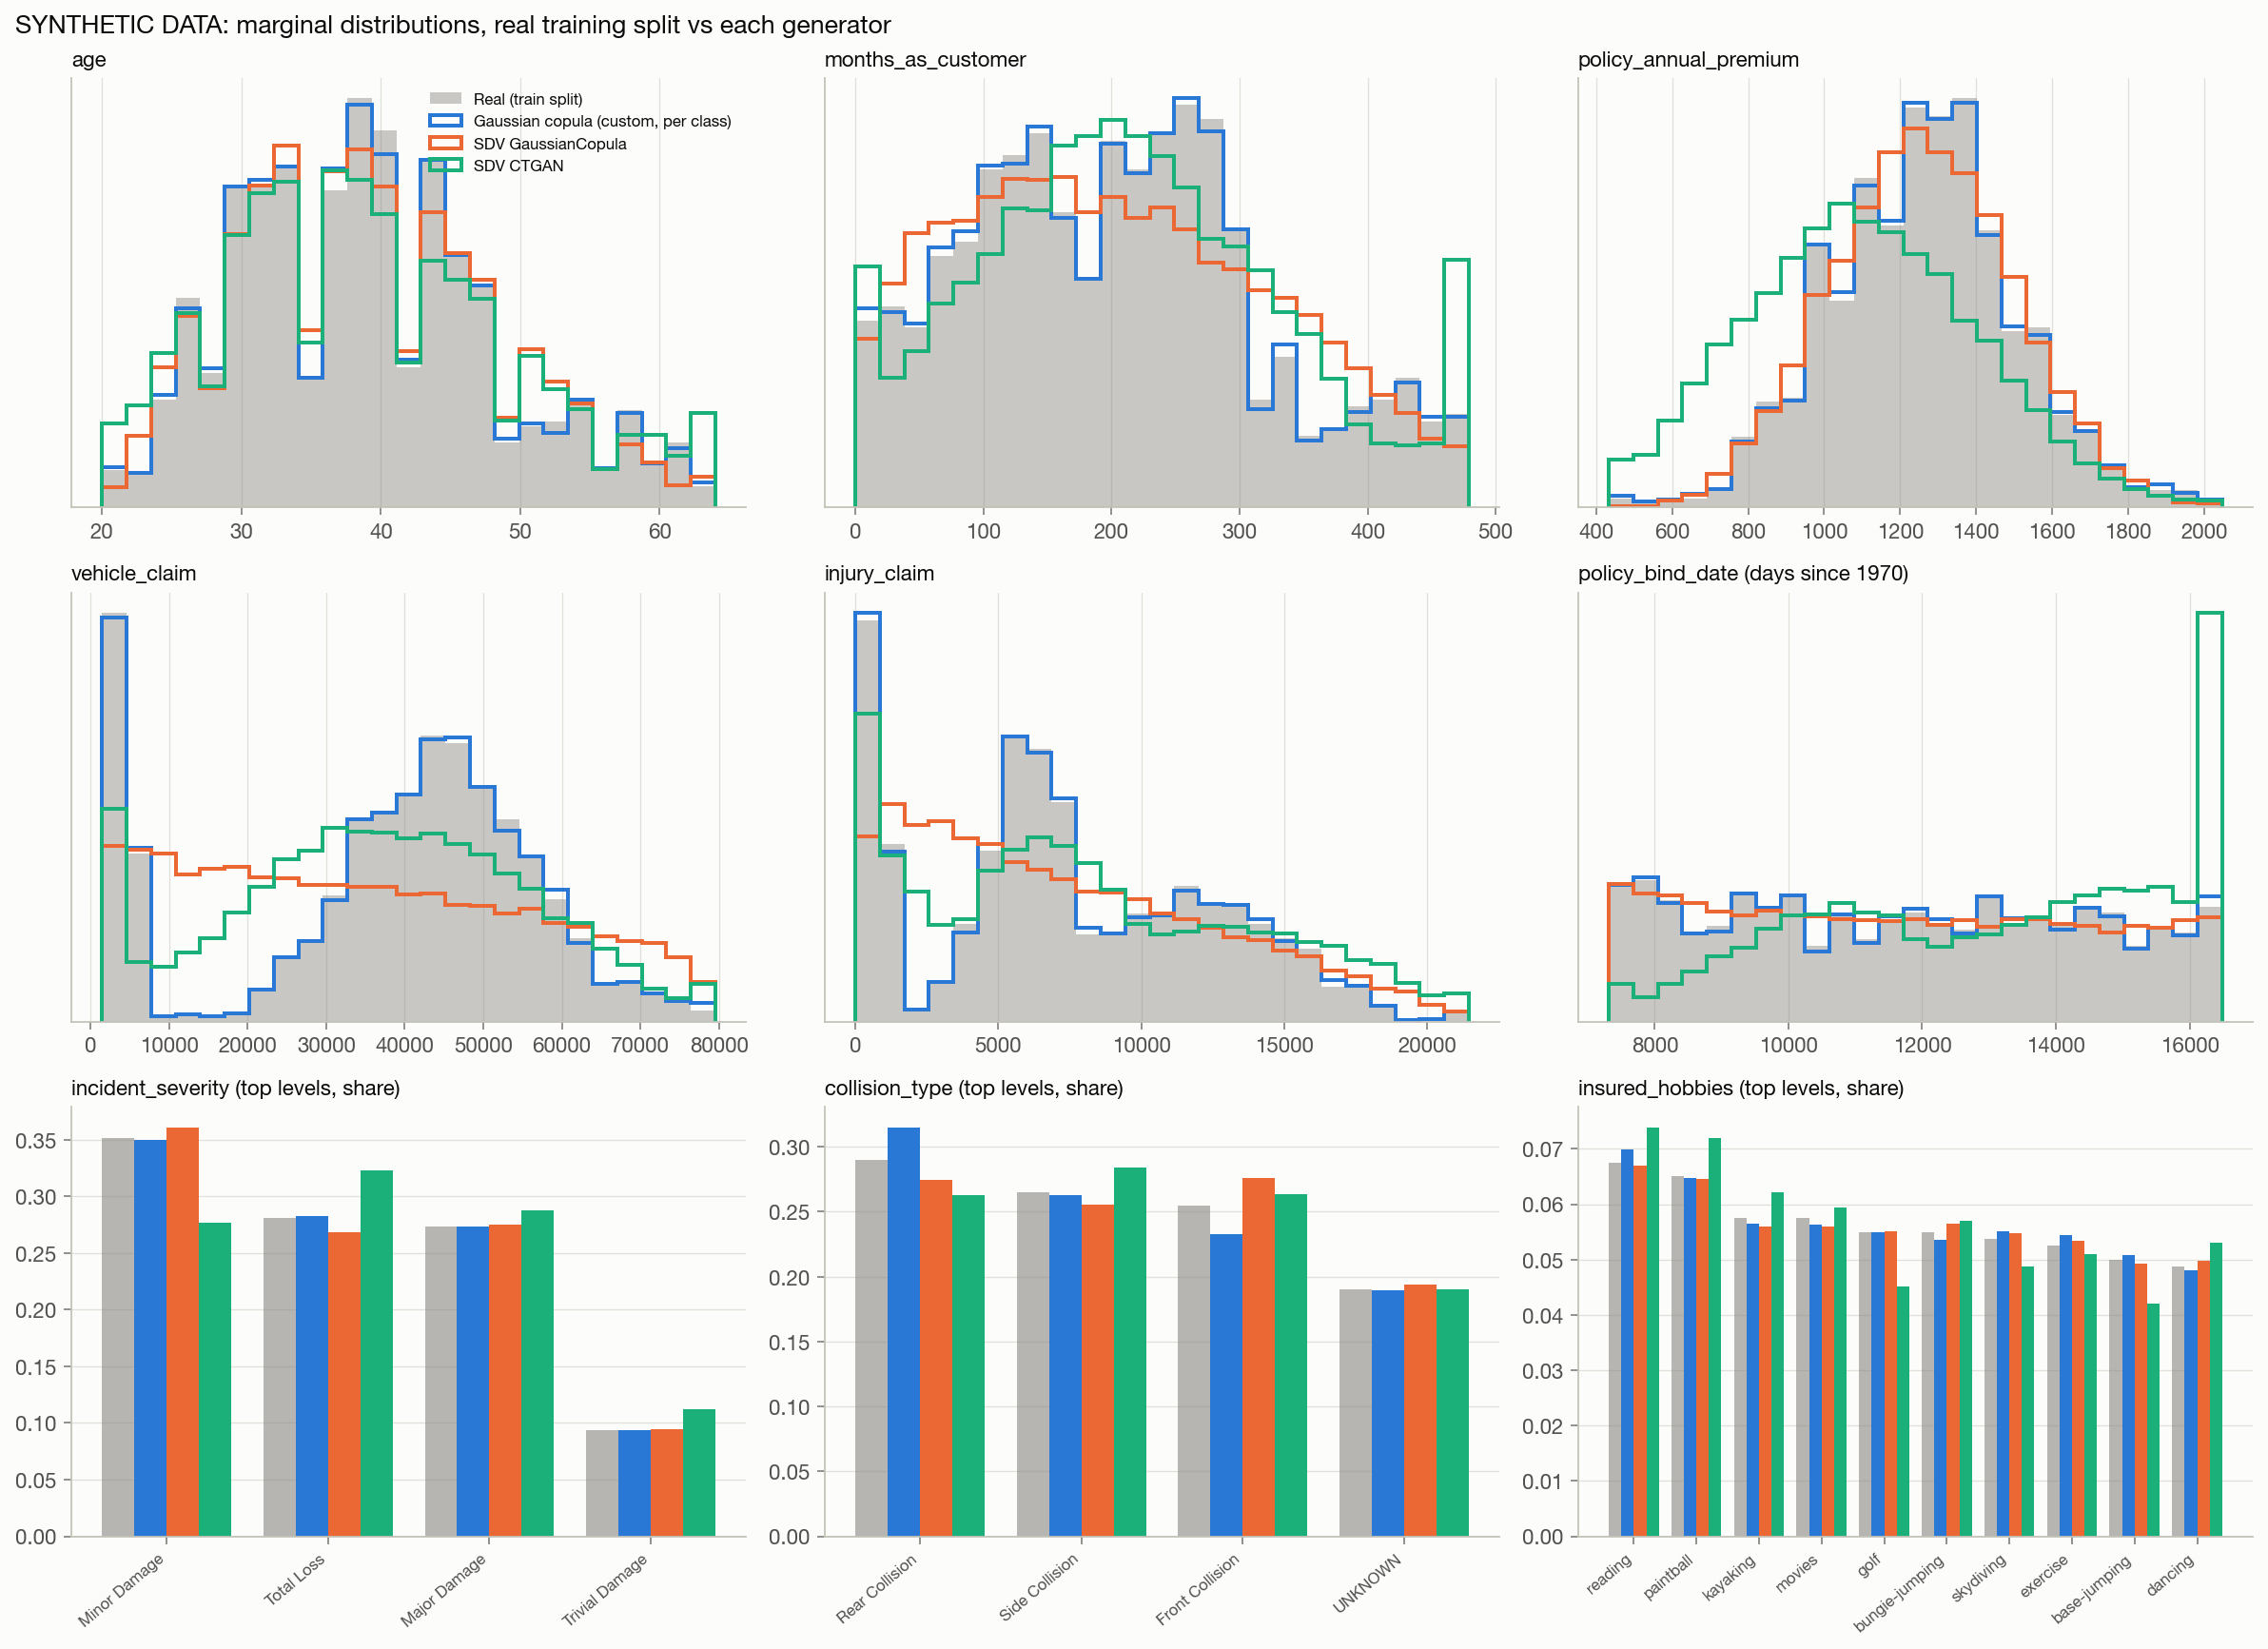

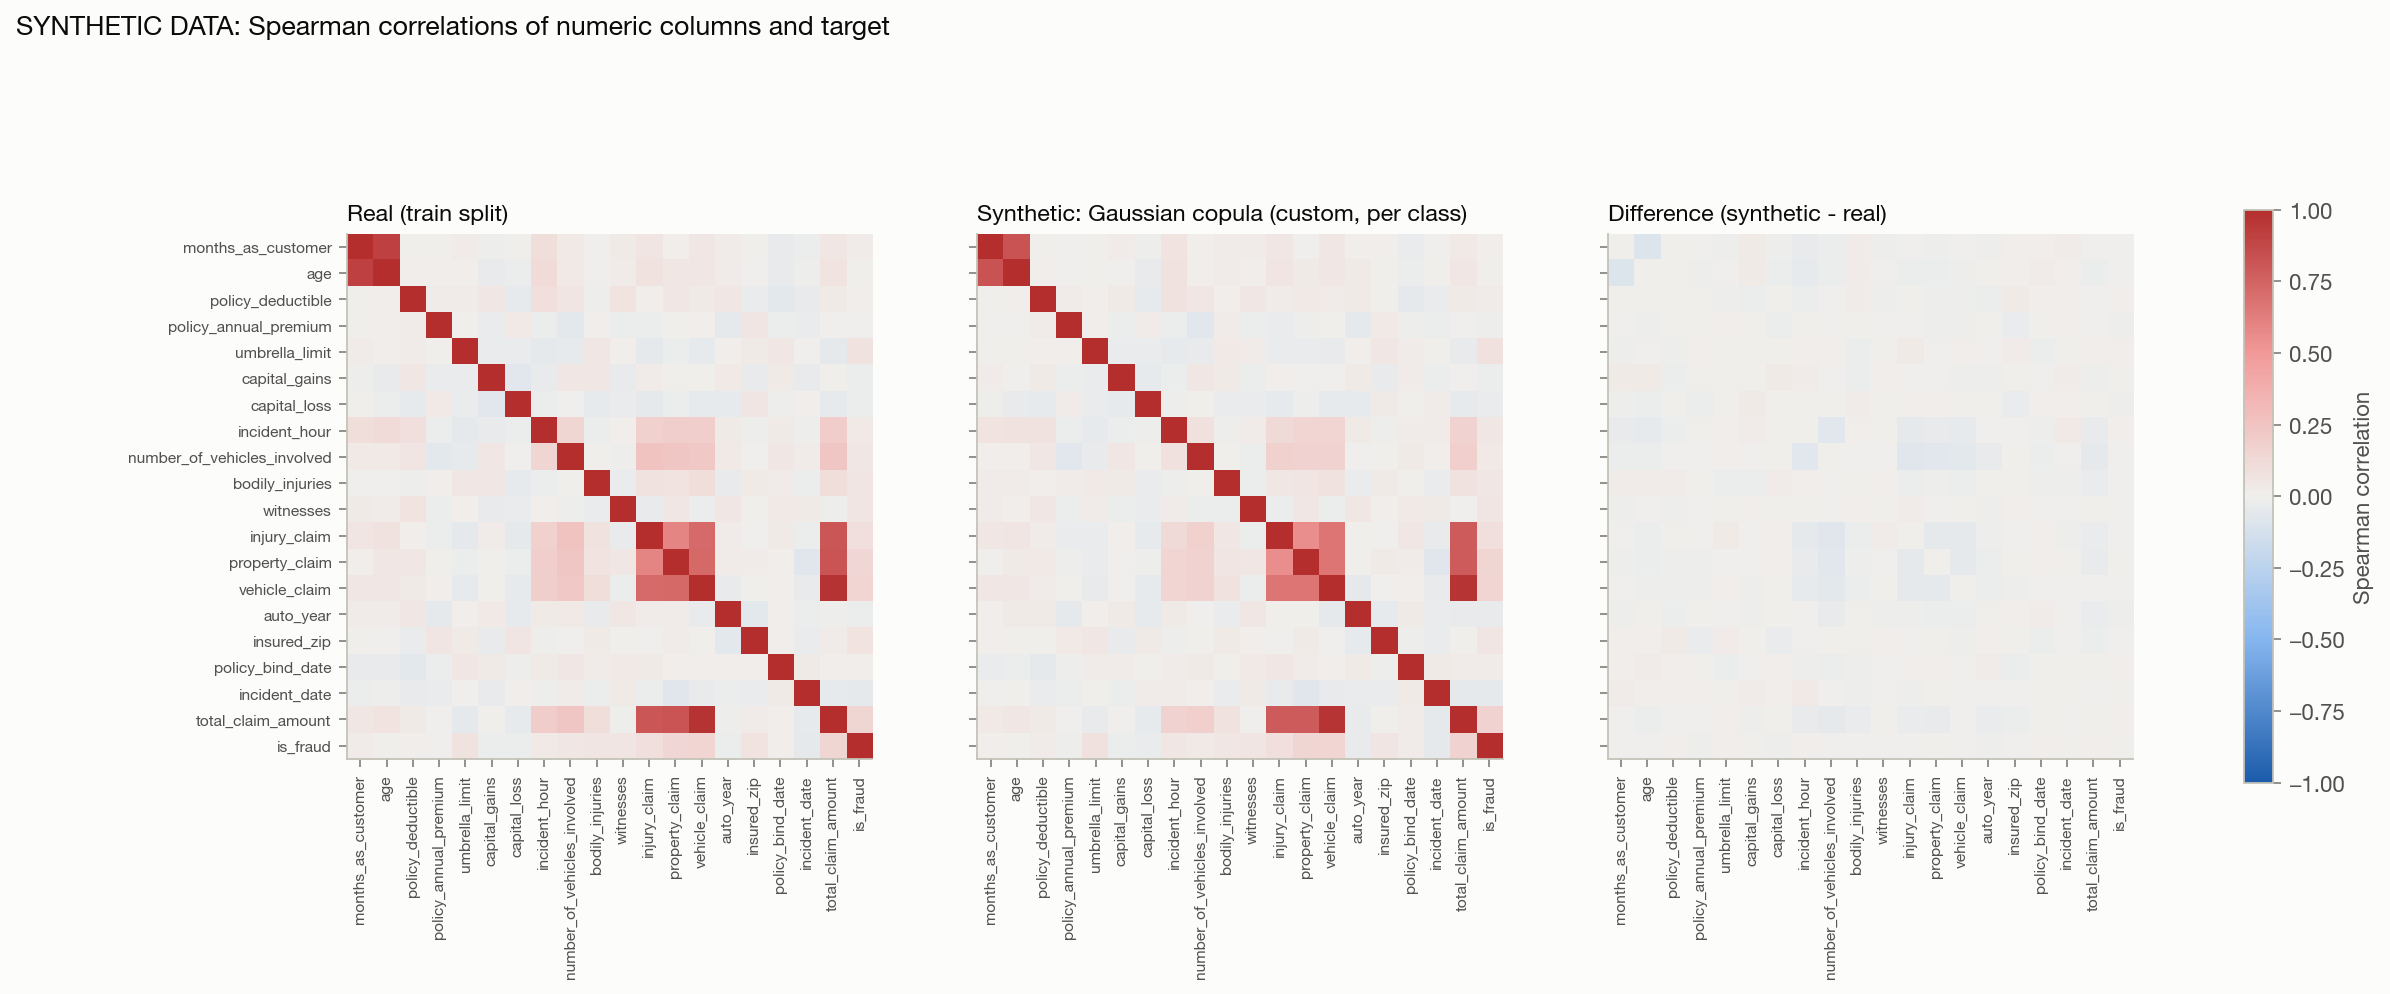

In [14]:
display(Image(FIG / 'synthetic_quality.png'))
display(Image(FIG / 'synthetic_marginals.png'))
display(Image(FIG / 'synthetic_correlations.png'))

## (b) SYNTHETIC data - scale benchmark and (c) TSTR

In [15]:
print(json.loads((MET / 'synthetic_dataset.json').read_text()))
pd.read_csv(MET / 'synthetic_scale_benchmark.csv')

{'generator': 'gaussian_copula_custom', 'n_rows': 500000, 'path': 'data/synthetic/SYNTHETIC_claims_gaussian_copula_custom_500000.parquet', 'fitted_on': 'real training split (800 rows)', 'rules_enforced': ['collision_type UNKNOWN iff incident is theft / parked car'], 'fraud_rate': 0.2475}


,model,n_train,fit_seconds,synthetic_test_pr_auc,synthetic_test_roc_auc,real_test_pr_auc_tstr,real_test_roc_auc_tstr
0,logreg_enet,1000,0.879,0.764,0.895,0.473,0.768
1,lightgbm,1000,0.519,0.803,0.913,0.549,0.840
2,xgboost,1000,0.251,0.786,0.905,0.503,0.806
3,catboost,1000,4.418,0.822,0.922,0.533,0.840
4,mlp,1000,2.776,0.782,0.901,0.485,0.779
5,random_forest,1000,6.363,0.742,0.891,0.610,0.841
6,gradient_boosting,1000,1.362,0.772,0.894,0.590,0.856
7,logreg_enet,10000,10.993,0.827,0.929,0.521,0.808
8,lightgbm,10000,1.981,0.858,0.942,0.548,0.835
9,xgboost,10000,0.808,0.833,0.930,0.553,0.845


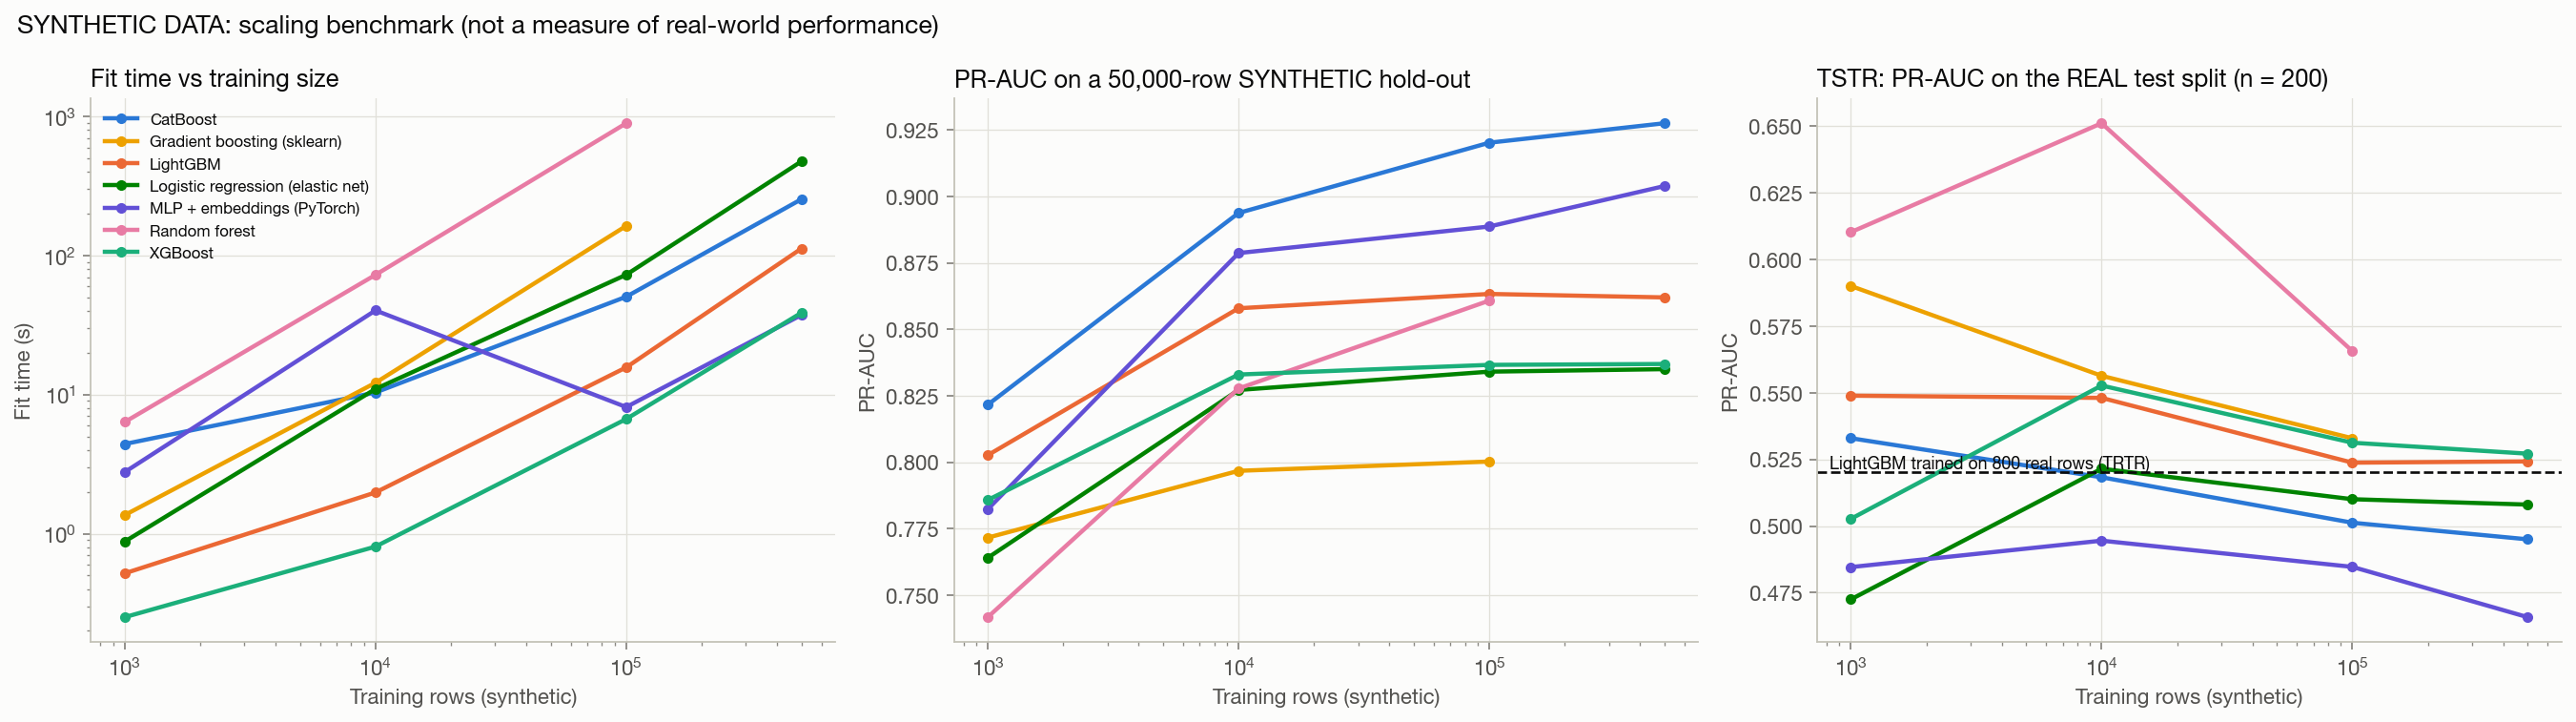

In [16]:
display(Image(FIG / 'synthetic_scale.png'))

## Conclusions

1. Using all relevant columns lifts every tuned model from chance level (ROC-AUC 0.50 in the previous 4-feature version) to test ROC-AUC 0.82-0.84 and PR-AUC 0.51-0.60.
2. After Holm correction, no model is significantly better than the CV-selected reference (CatBoost) on CV folds or on the test set; only the unpenalised logistic regression is clearly weaker on most metrics.
3. The signal comes almost entirely from `incident_severity` and `insured_hobbies`; claim amounts add nothing (no leakage).
4. Under the stated cost hypotheses (1,000 USD per investigation, 10,000 USD per missed fraud) the reference model saves 32 % versus investigating every claim; the benefit vanishes when a missed fraud costs 20 times an investigation or more.
5. Synthetic data reproduces the real signal (TSTR close to TRTR) but adds no information: synthetic hold-out scores are inflated and more synthetic rows do not improve performance on real claims.